In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%load_ext autoreload
%autoreload 2

from src.data import load_train
from src.config import FAMILIES, ATTACK_TO_FAMILY, METRICS_DIR, FIGURES_DIR
from src.evaluation import load_oof, wilson_ci, per_attack_recall, missed_destinations, fp_breakdown

X_train, y_train, meta_train = load_train()

# ---- ALIGNMENT TEST (the classic bug) ----
# OOF arrays are positional: oof[i] <-> X_train.iloc[i] <-> y_train.iloc[i] <-> meta_train.iloc[i].
derived = meta_train.map(ATTACK_TO_FAMILY)
assert (derived.values == y_train.values).all(), \
    "ALIGNMENT BUG: ATTACK_TO_FAMILY[meta_train.label] != y_train"
print(f"alignment OK for all {len(y_train)} rows: meta_train -> family == y_train")

# Positional arrays aligned with OOF outputs
y_true = y_train.values          # family
meta_true = meta_train.values    # attack name
print("train family counts:", dict(pd.Series(y_true).value_counts()))

alignment OK for all 116466 rows: meta_train -> family == y_train
train family counts: {'Normal': np.int64(70264), 'DoS': np.int64(43657), 'Probe': np.int64(1704), 'R2L': np.int64(799), 'U2R': np.int64(42)}


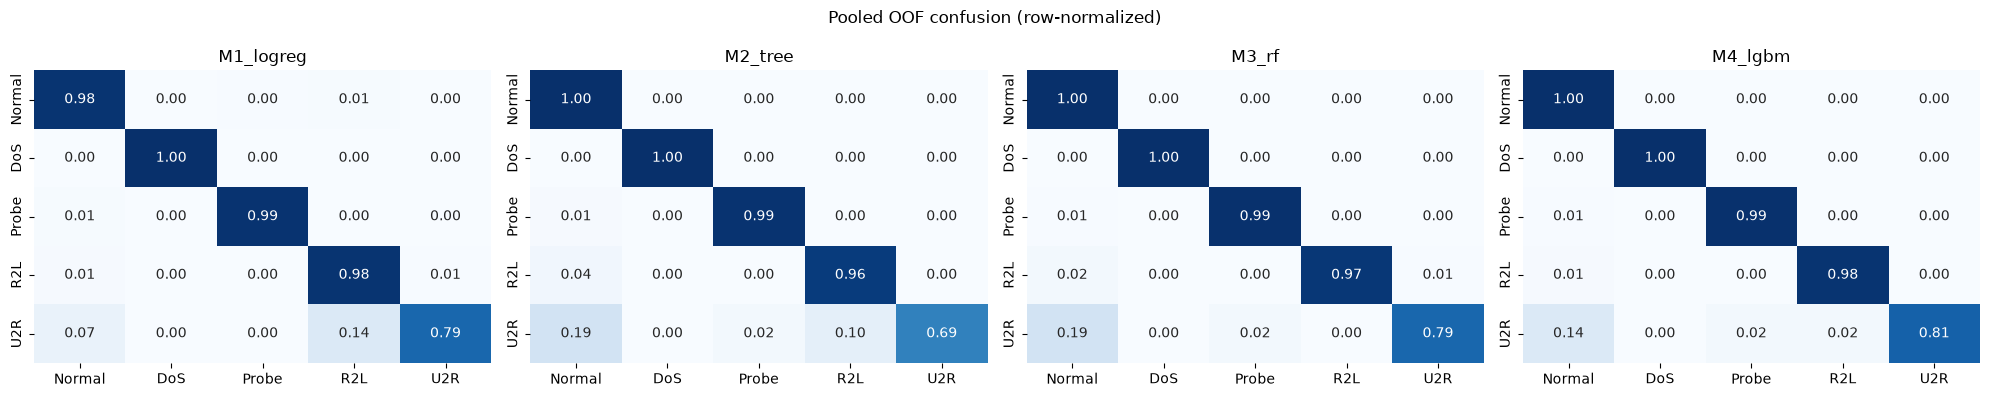

confusion totals and row sums verified for all models


In [2]:
from sklearn.metrics import confusion_matrix

MODELS = ["M1_logreg", "M2_tree", "M3_rf", "M4_lgbm"]
oof = {m: load_oof(m) for m in MODELS}   # {model: (y_pred, y_proba)}

fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4))
for ax, m in zip(axes, MODELS):
    yp, _ = oof[m]
    cm = confusion_matrix(y_true, yp, labels=FAMILIES)
    # structural checks
    assert cm.sum() == len(X_train), f"{m}: confusion total != {len(X_train)}"
    expected_rows = pd.Series(y_true).value_counts().reindex(FAMILIES).values
    assert np.array_equal(cm.sum(axis=1), expected_rows), f"{m}: row sums wrong"
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, ax=ax, annot=True, fmt=".2f", xticklabels=FAMILIES,
                yticklabels=FAMILIES, cmap="Blues", cbar=False, vmin=0, vmax=1)
    ax.set_title(m)
plt.suptitle("Pooled OOF confusion (row-normalized)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "p15_confusion_pooled.png", dpi=120); plt.show()
print("confusion totals and row sums verified for all models")

In [3]:
R2L_ATTACKS = [a for a, f in ATTACK_TO_FAMILY.items() if f == "R2L"]
U2R_ATTACKS = [a for a, f in ATTACK_TO_FAMILY.items() if f == "U2R"]
print("R2L attacks:", R2L_ATTACKS)
print("U2R attacks:", U2R_ATTACKS)

for family in ["R2L", "U2R"]:
    for m in MODELS:
        yp, _ = oof[m]
        tbl = per_attack_recall(meta_true, yp, family, ATTACK_TO_FAMILY)
        tbl.to_csv(METRICS_DIR / f"p15_per_attack_{m}_{family}.csv", index=False)
        print(f"\n=== {m} — {family} (pooled OOF) ===")
        print(tbl.to_string(index=False))
        # per-attack n must sum to the family count
        fam_n = int((y_true == family).sum())
        assert tbl["n"].sum() == fam_n, f"{m}/{family}: attack n doesn't sum to {fam_n}"
print("\nper-attack n sums to family counts for every model")

R2L attacks: ['ftp_write', 'guess_passwd', 'imap', 'multihop', 'phf', 'spy', 'warezclient', 'warezmaster']
U2R attacks: ['buffer_overflow', 'loadmodule', 'perl', 'rootkit']

=== M1_logreg — R2L (pooled OOF) ===
      attack family   n  k_correct   recall   ci_low  ci_high most_common_wrong
 warezclient    R2L 715        710 0.993007 0.983735 0.997009            Normal
guess_passwd    R2L  44         43 0.977273 0.881923 0.995977               U2R
 warezmaster    R2L  13         11 0.846154 0.577654 0.956742               U2R
        imap    R2L   9          9 1.000000 0.700855 1.000000                 -
   ftp_write    R2L   7          4 0.571429 0.250458 0.841780            Normal
    multihop    R2L   6          5 0.833333 0.436497 0.969947               U2R
         phf    R2L   3          2 0.666667 0.207660 0.938508            Normal
         spy    R2L   2          0 0.000000 0.000000 0.657620            Normal

=== M2_tree — R2L (pooled OOF) ===
      attack family   n  k_correc


=== M1_logreg — U2R (pooled OOF) ===
         attack family  n  k_correct   recall   ci_low  ci_high most_common_wrong
buffer_overflow    U2R 23         22 0.956522 0.790088 0.992283               R2L
     loadmodule    U2R  8          5 0.625000 0.305742 0.863156               R2L
        rootkit    U2R  8          3 0.375000 0.136844 0.694258            Normal
           perl    U2R  3          3 1.000000 0.438503 1.000000                 -



=== M2_tree — U2R (pooled OOF) ===
         attack family  n  k_correct   recall   ci_low  ci_high most_common_wrong
buffer_overflow    U2R 23         18 0.782609 0.580965 0.903360            Normal
     loadmodule    U2R  8          6 0.750000 0.409275 0.928521            Normal
        rootkit    U2R  8          2 0.250000 0.071479 0.590725            Normal
           perl    U2R  3          3 1.000000 0.438503 1.000000                 -

=== M3_rf — U2R (pooled OOF) ===
         attack family  n  k_correct   recall   ci_low  ci_high most_common_wrong
buffer_overflow    U2R 23         22 0.956522 0.790088 0.992283            Normal
     loadmodule    U2R  8          5 0.625000 0.305742 0.863156            Normal
        rootkit    U2R  8          3 0.375000 0.136844 0.694258            Normal
           perl    U2R  3          3 1.000000 0.438503 1.000000                 -

=== M4_lgbm — U2R (pooled OOF) ===
         attack family  n  k_correct   recall   ci_low  ci_high most_commo

In [4]:
for family in ["U2R", "R2L"]:
    print(f"\n=== Missed {family} destinations ===")
    for m in ["M2_tree", "M3_rf", "M4_lgbm"]:
        yp, _ = oof[m]
        dest = missed_destinations(y_true, yp, family)
        total_missed = int(dest.sum())
        to_normal = int(dest.get("Normal", 0))
        print(f"  {m:<10} missed={total_missed:>3}  -> Normal={to_normal:>3} "
              f"({to_normal/total_missed:.0%})  | {dest.to_dict()}")


=== Missed U2R destinations ===
  M2_tree    missed= 13  -> Normal=  8 (62%)  | {'Normal': 8, 'R2L': 4, 'Probe': 1}
  M3_rf      missed=  9  -> Normal=  8 (89%)  | {'Normal': 8, 'Probe': 1}
  M4_lgbm    missed=  8  -> Normal=  6 (75%)  | {'Normal': 6, 'R2L': 1, 'Probe': 1}

=== Missed R2L destinations ===
  M2_tree    missed= 35  -> Normal= 30 (86%)  | {'Normal': 30, 'U2R': 3, 'DoS': 1, 'Probe': 1}
  M3_rf      missed= 24  -> Normal= 19 (79%)  | {'Normal': 19, 'U2R': 4, 'DoS': 1}
  M4_lgbm    missed= 14  -> Normal= 10 (71%)  | {'Normal': 10, 'U2R': 3, 'DoS': 1}


In [5]:
for m in ["M4_lgbm", "M3_rf"]:
    yp, _ = oof[m]
    fp_df, n_fp = fp_breakdown(yp, y_true, X_train, by=("service", "flag"))
    print(f"\n=== {m}: {n_fp} false positives ===")
    for col in ["service", "flag"]:
        sub = fp_df[fp_df["by"] == col].head(8)
        print(f" by {col}:")
        print(sub[[col, "n_fp", "share_of_fp"]].to_string(index=False))


=== M4_lgbm: 19 false positives ===
 by service:
 service  n_fp  share_of_fp
  telnet     6     0.315789
ftp_data     5     0.263158
 private     2     0.105263
domain_u     1     0.052632
   other     1     0.052632
     IRC     1     0.052632
   ecr_i     1     0.052632
   tim_i     1     0.052632
 by flag:
flag  n_fp  share_of_fp
  SF    14     0.736842
  S1     2     0.105263
RSTO     2     0.105263
 REJ     1     0.052632

=== M3_rf: 17 false positives ===
 by service:
 service  n_fp  share_of_fp
ftp_data     9     0.529412
  telnet     5     0.294118
   ecr_i     1     0.058824
 private     1     0.058824
    http     1     0.058824
 by flag:
flag  n_fp  share_of_fp
  SF    13     0.764706
  S0     1     0.058824
  S1     1     0.058824
RSTO     1     0.058824
 REJ     1     0.058824


In [6]:
for m in ["M3_rf", "M4_lgbm"]:
    fd = pd.read_csv(METRICS_DIR / f"cv_results_{m}.csv")
    print(f"{m} per-fold U2R recall: {fd['recall_U2R'].round(3).tolist()}")
    print(f"  -> each fold validates on ~{(y_true=='U2R').sum()//5} U2R rows, "
          f"so one miss swings recall by ~{1/((y_true=='U2R').sum()//5):.0%}")

M3_rf per-fold U2R recall: [0.778, 0.625, 0.875, 0.875, 0.778]
  -> each fold validates on ~8 U2R rows, so one miss swings recall by ~12%
M4_lgbm per-fold U2R recall: [0.778, 0.75, 1.0, 0.75, 0.778]


  -> each fold validates on ~8 U2R rows, so one miss swings recall by ~12%


In [7]:
m = "M4_lgbm"
yp, _ = oof[m]
u2r = y_true == "U2R"
caught = u2r & (yp == "U2R")
missed = u2r & (yp != "U2R")
normal = y_true == "Normal"

probe_cols = ["duration", "src_bytes", "dst_bytes", "hot", "num_root",
              "num_file_creations", "srv_count"]
print(f"U2R caught={int(caught.sum())}, missed={int(missed.sum())}")
rows = []
for c in probe_cols:
    rows.append({"feature": c,
                 "missed_U2R_mean": X_train.iloc[missed][c].mean(),
                 "caught_U2R_mean": X_train.iloc[caught][c].mean(),
                 "Normal_mean": X_train.iloc[normal][c].mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

U2R caught=34, missed=8
           feature  missed_U2R_mean  caught_U2R_mean  Normal_mean
          duration            53.75            66.71       188.62
         src_bytes           260.75          1055.18      1242.98
         dst_bytes          1278.38          5981.62      3695.83
               hot             0.62             1.65         0.05
          num_root             0.00             1.00         0.07
num_file_creations             0.75             0.91         0.01
         srv_count             1.25             1.21        11.99


In [8]:
from sklearn.base import clone
from src.models import get_models

pipe_m2 = clone(get_models()["M2_tree"])
pipe_m2.fit(X_train, y_train)
tree = pipe_m2.named_steps["clf"]
X_t = pipe_m2.named_steps["pre"].transform(X_train)
leaves = tree.apply(X_t)

u2r_idx = np.where(y_true == "U2R")[0]
u2r_leaves = leaves[u2r_idx]
uniq, counts = np.unique(leaves, return_counts=True)
leaf_size = dict(zip(uniq, counts))

print("Leaves used by U2R rows (tests Entry 9c 'memorizes tiny U2R leaves'):")
for lf in np.unique(u2r_leaves):
    n_u2r = int((u2r_leaves == lf).sum())
    print(f"  leaf {lf}: total size={leaf_size[lf]:>3}, U2R rows={n_u2r}")

Leaves used by U2R rows (tests Entry 9c 'memorizes tiny U2R leaves'):
  leaf 58: total size=  2, U2R rows=1
  leaf 88: total size=  2, U2R rows=1
  leaf 93: total size=  6, U2R rows=6
  leaf 94: total size=  3, U2R rows=3
  leaf 131: total size=  2, U2R rows=1
  leaf 203: total size=  3, U2R rows=3
  leaf 205: total size= 24, U2R rows=24
  leaf 209: total size=  2, U2R rows=2
  leaf 210: total size=  2, U2R rows=1


Notebook 04 — Phase 18 cells

In [9]:
import json
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer, f1_score
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

from src.data import load_train
from src.config import (
    FAMILIES, SEED, METRICS_DIR, MODELS_DIR, FIGURES_DIR, 
    PROJECT_ROOT, USE_CLASS_WEIGHT, USE_ENGINEERED, CATEGORICAL_COLS
)
from src.evaluation import (
    load_oof, decide, threshold_sweep, choose_tau, 
    multiclass_metrics, binary_view, attack_score
)
from src.models import get_models

X_train, y_train, _ = load_train()
y_true = y_train.values

# Load the winner from Phase 17
with open(MODELS_DIR / "selection_decision.json") as f:
    decision = json.load(f)
winner = decision["winner"]
config_choice = decision["chosen_config"][winner]

print(f"Winner: {winner} ({config_choice})")

# Issue 2 Fix: OOF probabilities must match the selected model configuration
if config_choice == "tuned":
    print(f"Winner {winner} was tuned. Regenerating OOF probabilities for tuned configuration...")
    from sklearn.model_selection import StratifiedKFold
    from src.evaluation import save_oof
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof_proba = np.zeros((len(y_train), len(FAMILIES)), dtype=np.float64)
    with open(MODELS_DIR / "best_params.json") as f:
        best_params = json.load(f)
    pipe = get_models(class_weight=USE_CLASS_WEIGHT, engineered=USE_ENGINEERED)[winner]
    pipe.set_params(**best_params[winner])
    for fold, (trn_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
        pipe.fit(X_train.iloc[trn_idx], y_train.iloc[trn_idx])
        oof_proba[val_idx] = pipe.predict_proba(X_train.iloc[val_idx])
    save_oof(winner, y_true, oof_proba)
else:
    print(f"Winner {winner} uses default configuration. Loading frozen OOF probabilities from Phase 14...")
    _, oof_proba = load_oof(winner)

print(f"OOF proba shape: {oof_proba.shape}")

Winner: M4_lgbm (default)
Winner M4_lgbm uses default configuration. Loading frozen OOF probabilities from Phase 14...
OOF proba shape: (116466, 5)


In [10]:
# 1. FPR non-increasing, FNR non-decreasing
taus = np.linspace(0, 1, 50)
sweep_test = threshold_sweep(y_true, oof_proba, taus)
assert all(sweep_test["fpr"].iloc[i] >= sweep_test["fpr"].iloc[i+1] for i in range(len(sweep_test)-1))
assert all(sweep_test["fnr"].iloc[i] <= sweep_test["fnr"].iloc[i+1] for i in range(len(sweep_test)-1))
print("FPR is non-increasing and FNR is non-decreasing with tau")

# 2. Edge cases
assert np.isclose(sweep_test.iloc[0]["fpr"], 1.0), "tau=0 should alert on everything (FPR=1)"
assert np.isclose(sweep_test.iloc[-1]["fpr"], 0.0), "tau=1 should alert on nothing (FPR=0)"
print("tau=0 -> FPR=1; tau=1 -> FPR=0")

# 3. decide(proba, 0.5) vs plain argmax
plain_argmax = np.array(FAMILIES)[oof_proba.argmax(axis=1)]
tau_05_preds = decide(oof_proba, 0.5)
diff_mask = plain_argmax != tau_05_preds
n_diff = diff_mask.sum()
print(f"\ndecide(tau=0.5) differs from plain argmax on {n_diff} rows.")
if n_diff > 0:
    print("  -> Happens when P(Normal) < 0.5, but no single attack family has > P(Normal).")

FPR is non-increasing and FNR is non-decreasing with tau
tau=0 -> FPR=1; tau=1 -> FPR=0

decide(tau=0.5) differs from plain argmax on 1 rows.
  -> Happens when P(Normal) < 0.5, but no single attack family has > P(Normal).


In [11]:
taus = np.linspace(0.0, 1.0, 1000)
sweep = threshold_sweep(y_true, oof_proba, taus)

# Pre-registered rule: lowest tau with FPR <= 0.001 (0.1%)
target_fpr = 0.001
best_tau = choose_tau(sweep, fpr_max=target_fpr)

best_row = sweep.iloc[(sweep["tau"] - best_tau).abs().argsort()[:1]]
print(f"=== Threshold Selection ===")
print(f"Target FPR ceiling: {target_fpr:.1%}")
print(f"Chosen tau: {best_tau:.4f}")
print(f"At this tau:")
print(f"  FPR      : {best_row['fpr'].iloc[0]:.4%}")
print(f"  Macro-F1 : {best_row['macro_f1'].iloc[0]:.4f}")
print(f"  R2L recall: {best_row['recall_R2L'].iloc[0]:.4f}")
print(f"  U2R recall: {best_row['recall_U2R'].iloc[0]:.4f}")
print(f"  False alarms per 100k Normal: {best_row['fp_per_100k_normal'].iloc[0]:.1f}")

sweep.to_csv(METRICS_DIR / "p18_threshold_sweep.csv", index=False)

=== Threshold Selection ===
Target FPR ceiling: 0.1%
Chosen tau: 0.0020
At this tau:
  FPR      : 0.0911%
  Macro-F1 : 0.9477
  R2L recall: 0.9887
  U2R recall: 0.9048
  False alarms per 100k Normal: 91.1


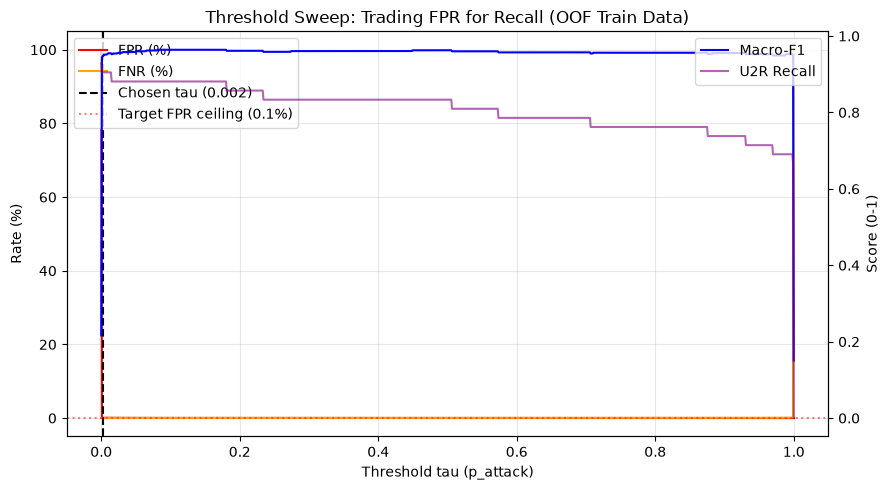

In [12]:
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(sweep["tau"], sweep["fpr"] * 100, color="red", label="FPR (%)")
ax1.plot(sweep["tau"], sweep["fnr"] * 100, color="orange", label="FNR (%)")
ax1.axvline(best_tau, color="black", linestyle="--", label=f"Chosen tau ({best_tau:.3f})")
ax1.axhline(target_fpr * 100, color="red", linestyle=":", alpha=0.5, label=f"Target FPR ceiling ({target_fpr:.1%})")
ax1.set_xlabel("Threshold tau (p_attack)")
ax1.set_ylabel("Rate (%)")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(sweep["tau"], sweep["macro_f1"], color="blue", label="Macro-F1")
ax2.plot(sweep["tau"], sweep["recall_U2R"], color="purple", alpha=0.6, label="U2R Recall")
ax2.set_ylabel("Score (0-1)")
ax2.legend(loc="upper right")

plt.title("Threshold Sweep: Trading FPR for Recall (OOF Train Data)")
fig.tight_layout()
plt.savefig(FIGURES_DIR / "p18_threshold_sweep.png", dpi=120)
plt.show()

In [13]:
import re
from pathlib import Path
from src.config import PROJECT_ROOT

config_path = PROJECT_ROOT / "src" / "config.py"
assert config_path.exists(), f"Config file not found at {config_path}"

text = config_path.read_text()
# Replace the placeholder with the actual float
new_text = re.sub(r"ALERT_TAU\s*=\s*[\d\.]+", f"ALERT_TAU = {best_tau:.6f}", text)
config_path.write_text(new_text)
print(f"ALERT_TAU frozen in src/config.py as {best_tau:.6f}")

ALERT_TAU frozen in src/config.py as 0.002002


In [14]:
from sklearn.base import clone
from sklearn.metrics import make_scorer, f1_score

# We need a holdout set from TRAIN to score permutation. NEVER use the test set.
X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.3, random_state=SEED, stratify=y_train
)

# Build and fit the winner pipeline using FROZEN configuration settings (Issue 1 Fix)
pipe = get_models(class_weight=USE_CLASS_WEIGHT, engineered=USE_ENGINEERED)[winner]
if config_choice == "tuned":
    with open(MODELS_DIR / "best_params.json") as f:
        best_params = json.load(f)
    pipe.set_params(**best_params[winner])

pipe.fit(X_tr_raw, y_tr)

scorer = make_scorer(f1_score, average="macro", labels=FAMILIES, zero_division=0)

# Permute RAW columns. The pipeline handles feature engineering and preprocessing internally.
print("Computing permutation importance on holdout split (39 raw features, 5 repeats)...")
perm_result = permutation_importance(
    pipe, X_val_raw, y_val, 
    n_repeats=5, random_state=SEED, 
    scoring=scorer, n_jobs=-1
)

perm_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

print("Top 15 Permutation Importances (raw features):")
print(perm_df.head(15).to_string(index=False))

# Column count test
assert len(perm_df) == X_train.shape[1], "Permutation must operate on raw columns, not one-hot!"
print(f"Permutation importance count ({len(perm_df)}) matches raw feature count ({X_train.shape[1]})")

perm_df.to_csv(METRICS_DIR / "p18_permutation_importance.csv", index=False)

Computing permutation importance on holdout split (39 raw features, 5 repeats)...


Top 15 Permutation Importances (raw features):
                    feature  importance_mean  importance_std
                  src_bytes         0.176515        0.011397
         dst_host_srv_count         0.035450        0.010994
                  dst_bytes         0.026356        0.008043
                    service         0.016582        0.011954
                   duration         0.006955        0.001114
             is_guest_login         0.006827        0.000000
             wrong_fragment         0.003672        0.000006
     dst_host_diff_srv_rate         0.003361        0.000688
dst_host_same_src_port_rate         0.003174        0.000505
              protocol_type         0.002436        0.002985
       dst_host_serror_rate         0.001791        0.000549
                        hot         0.001288        0.000000
              diff_srv_rate         0.000771        0.000197
           num_access_files         0.000427        0.000000
         num_file_creations         0.

In [15]:
from scipy.stats import spearmanr
from src.config import CATEGORICAL_COLS

# Extract impurity-based (MDI) importance from the fitted model
clf = pipe.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    pre = pipe.named_steps["pre"]
    feat_names = pre.get_feature_names_out()
    
    # Map preprocessed/one-hot features back to source raw columns (Issue 4 Fix)
    def map_to_raw(fn):
        prefix, name = fn.split("__", 1)
        if prefix == "cat":
            for c in CATEGORICAL_COLS:
                if name.startswith(c + "_"):
                    return c
        return name

    mapped_sources = [map_to_raw(fn) for fn in feat_names]
    
    # Create MDI dataframe for all preprocessed features
    mdi_raw_df = pd.DataFrame({
        "preprocessed_feature": feat_names,
        "source_feature": mapped_sources,
        "mdi_importance": clf.feature_importances_
    })
    
    # Aggregate MDI importance by source feature (summing across one-hot levels)
    mdi_agg = mdi_raw_df.groupby("source_feature")["mdi_importance"].sum().reset_index()
    mdi_agg = mdi_agg.sort_values("mdi_importance", ascending=False)
    
    # Merge on the 39 raw features present in X_train for rank correlation
    merged_imp = perm_df.merge(mdi_agg, left_on="feature", right_on="source_feature", how="inner")
    
    corr, p_val = spearmanr(merged_imp["importance_mean"], merged_imp["mdi_importance"])
    
    print("=== Feature Importance Comparison ===")
    print(f"Preprocessed features (MDI): {len(feat_names)}")
    print(f"Aggregated source features: {len(mdi_agg)}")
    print(f"Shared raw features evaluated: {len(merged_imp)}")
    print(f"Spearman rank correlation: {corr:.4f} (p-value: {p_val:.4e})\n")
    
    print("Top 10 Permutation Importance (Macro-F1 Drop on Holdout):")
    print(perm_df[["feature", "importance_mean", "importance_std"]].head(10).to_string(index=False))
    
    print("\nTop 10 Aggregated MDI Importance (Split Gain):")
    print(mdi_agg.head(10).to_string(index=False))
    
    # Save comparison table
    merged_imp.to_csv(METRICS_DIR / "p18_feature_importance_comparison.csv", index=False)
    
elif hasattr(clf, "coef_"):
    print("Linear model: evaluate coefficients vs permutation importance.")

=== Feature Importance Comparison ===
Preprocessed features (MDI): 118
Aggregated source features: 43
Shared raw features evaluated: 39
Spearman rank correlation: 0.4864 (p-value: 1.6931e-03)

Top 10 Permutation Importance (Macro-F1 Drop on Holdout):
                    feature  importance_mean  importance_std
                  src_bytes         0.176515        0.011397
         dst_host_srv_count         0.035450        0.010994
                  dst_bytes         0.026356        0.008043
                    service         0.016582        0.011954
                   duration         0.006955        0.001114
             is_guest_login         0.006827        0.000000
             wrong_fragment         0.003672        0.000006
     dst_host_diff_srv_rate         0.003361        0.000688
dst_host_same_src_port_rate         0.003174        0.000505
              protocol_type         0.002436        0.002985

Top 10 Aggregated MDI Importance (Split Gain):
             source_feature  m

Notebook 04 — Phase 19 cells: Single Final Evaluation on Locked Test Set

**Methodological Framing & Scientific Qualification (Issue 3):**
The held-out test evaluation provides our final unbiased performance estimate strictly within the KDD Cup 1999 benchmark distribution, proving that preprocessing, feature engineering, and model selection did not overfit or leak across the 80/20 train/test split. It does not automatically guarantee performance under real-world temporal distribution drift, zero-day vulnerabilities, or live SOC packet anomalies. All rare-class point estimates are reported alongside Wilson 95% score confidence intervals to reflect small-sample binomial variance honestly.

In [16]:
import json
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import learning_curve
from sklearn.metrics import confusion_matrix, f1_score, make_scorer
import matplotlib.pyplot as plt

from src.data import load_train, load_test
from src.config import (FAMILIES, METRICS_DIR, MODELS_DIR, FIGURES_DIR, 
                        ALERT_TAU, SEED, USE_CLASS_WEIGHT, USE_ENGINEERED)
from src.models import get_models
from src.evaluation import (evaluate_test, gap_table, wilson_ci, 
                            get_cv, _reorder_proba_to_families, decide)

X_train, y_train, _ = load_train()
X_test, y_test, _ = load_test()  # <--- THE LOCKED TEST SET

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")

Train size: 116466
Test size: 29117


In [17]:
with open(MODELS_DIR / "best_params.json") as f:
    best_params = json.load(f)
    
with open(MODELS_DIR / "selection_decision.json") as f:
    decision = json.load(f)

winner = decision["winner"]
config_choices = decision["chosen_config"]
print(f"Winner: {winner} ({config_choices[winner]}), ALERT_TAU: {ALERT_TAU}")

fitted_models = {}
for name in ["M1_logreg", "M2_tree", "M3_rf", "M4_lgbm"]:
    pipe = get_models(class_weight=USE_CLASS_WEIGHT, engineered=USE_ENGINEERED)[name]
    if config_choices[name] == "tuned":
        pipe.set_params(**best_params[name])
        
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    print(f"Fitted {name} ({config_choices[name]}) on full train.")
    
# Dummy baseline
pipe_dummy = get_models(class_weight=USE_CLASS_WEIGHT, engineered=USE_ENGINEERED)["M0_dummy"]
pipe_dummy.fit(X_train, y_train)
fitted_models["M0_dummy"] = pipe_dummy
print("Fitted M0_dummy.")

Winner: M4_lgbm (default), ALERT_TAU: 0.002002


Fitted M1_logreg (tuned) on full train.


Fitted M2_tree (default) on full train.


Fitted M3_rf (default) on full train.


Fitted M4_lgbm (default) on full train.
Fitted M0_dummy.


In [18]:
test_lock = METRICS_DIR / ".test_evaluated"
test_results = {}
test_preds = {}
test_probas = {}

required_model_names = list(fitted_models.keys()) + [f"{winner}_tau"]

# Fail-safe lock check: Never silently evaluate the test set again.
if test_lock.exists():
    if not (METRICS_DIR / "test_results.json").exists():
        raise RuntimeError("Test lock exists (.test_evaluated) but test_results.json is missing; refusing to re-evaluate the locked test set.")
    with open(METRICS_DIR / "test_results.json") as f:
        test_results = json.load(f)
    missing_entries = [m for m in required_model_names if m not in test_results]
    if missing_entries:
        raise RuntimeError(f"Test lock exists but test_results.json is incomplete (missing: {missing_entries}); refusing to re-evaluate.")
    missing_npz = [m for m in required_model_names if not (METRICS_DIR / f"test_{m}.npz").exists()]
    if missing_npz:
        raise RuntimeError(f"Test lock exists but prediction files are missing for: {missing_npz}; refusing to re-evaluate.")
    for name in required_model_names:
        data = np.load(METRICS_DIR / f"test_{name}.npz", allow_pickle=True)
        test_preds[name] = data["y_pred"]
        test_probas[name] = data["y_proba"]
    print("[Lock Active] Test set was already evaluated! Loading existing results from disk...")
    print("Successfully loaded test predictions and metrics from disk. Test set was NOT re-evaluated.")
else:
    print("Evaluating models on the locked test set (single-pass execution)...")
    for name, pipe in fitted_models.items():
        # Standard argmax evaluation for all models
        metrics_argmax, y_pred_argmax, proba = evaluate_test(pipe, X_test, y_test, tau=None)
        test_results[name] = metrics_argmax
        test_preds[name] = y_pred_argmax
        test_probas[name] = proba
        np.savez_compressed(METRICS_DIR / f"test_{name}.npz", y_pred=y_pred_argmax, y_proba=proba)
        print(f"{name} (argmax): Test Macro-F1 = {metrics_argmax['macro_f1']:.4f}, FPR = {metrics_argmax['fpr']:.5f}")

        # For the champion, also evaluate and store the calibrated threshold policy
        if name == winner:
            metrics_tau, y_pred_tau, _ = evaluate_test(pipe, X_test, y_test, tau=ALERT_TAU)
            test_results[f"{winner}_tau"] = metrics_tau
            test_preds[f"{winner}_tau"] = y_pred_tau
            test_probas[f"{winner}_tau"] = proba
            np.savez_compressed(METRICS_DIR / f"test_{winner}_tau.npz", y_pred=y_pred_tau, y_proba=proba)
            print(f"{winner} (tau={ALERT_TAU:.4f}): Test Macro-F1 = {metrics_tau['macro_f1']:.4f}, FPR = {metrics_tau['fpr']:.5f}")

    # Save all results to test_results.json and test_summary.csv
    with open(METRICS_DIR / "test_results.json", "w") as f:
        json.dump(test_results, f, indent=2)
    pd.DataFrame(test_results).T.to_csv(METRICS_DIR / "test_summary.csv")
    
    # Create lock file
    with open(test_lock, "w") as f:
        f.write(f"Test evaluated on {pd.Timestamp.now().isoformat()}\n")
        f.write(f"Winner: {winner}, Tau: {ALERT_TAU}\n")
    print("Saved test_results.json, test_summary.csv, and created .test_evaluated lock file.")

[Lock Active] Test set was already evaluated! Loading existing results from disk...
Successfully loaded test predictions and metrics from disk. Test set was NOT re-evaluated.


In [19]:
test_counts = y_test.value_counts()
print("Test set class counts:")
print(test_counts)

models_to_report = [f"{winner}_tau", winner, "M3_rf", "M2_tree"]
for name in models_to_report:
    y_pred = test_preds[name]
    tau_str = f"tau={ALERT_TAU:.4f}" if "_tau" in name else "argmax"
    print(f"\n=== Test Breakdown: {name} ({tau_str}) ===")
    
    # U2R
    n_u2r = int((y_test == "U2R").sum())
    k_u2r = int(((y_test == "U2R") & (y_pred == "U2R")).sum())
    ci_u2r = wilson_ci(k_u2r, n_u2r)
    print(f"U2R: {k_u2r} / {n_u2r} ({k_u2r/n_u2r:.1%}), Wilson 95% CI: [{ci_u2r[0]:.1%}, {ci_u2r[1]:.1%}]")
    
    # R2L
    n_r2l = int((y_test == "R2L").sum())
    k_r2l = int(((y_test == "R2L") & (y_pred == "R2L")).sum())
    ci_r2l = wilson_ci(k_r2l, n_r2l)
    print(f"R2L: {k_r2l} / {n_r2l} ({k_r2l/n_r2l:.1%}), Wilson 95% CI: [{ci_r2l[0]:.1%}, {ci_r2l[1]:.1%}]")
    
    # FPR (Normal)
    n_normal = int((y_test == "Normal").sum())
    k_fp = int(((y_test == "Normal") & (y_pred != "Normal")).sum())
    ci_fp = wilson_ci(k_fp, n_normal)
    print(f"FPR: {k_fp} / {n_normal} false alarms ({k_fp/n_normal:.4%}), Wilson 95% CI: [{ci_fp[0]:.4%}, {ci_fp[1]:.4%}]")

Test set class counts:
family
Normal    17567
DoS       10914
Probe       426
R2L         200
U2R          10
Name: count, dtype: int64

=== Test Breakdown: M4_lgbm_tau (tau=0.0020) ===
U2R: 9 / 10 (90.0%), Wilson 95% CI: [59.6%, 98.2%]
R2L: 198 / 200 (99.0%), Wilson 95% CI: [96.4%, 99.7%]
FPR: 19 / 17567 false alarms (0.1082%), Wilson 95% CI: [0.0693%, 0.1689%]

=== Test Breakdown: M4_lgbm (argmax) ===
U2R: 9 / 10 (90.0%), Wilson 95% CI: [59.6%, 98.2%]
R2L: 198 / 200 (99.0%), Wilson 95% CI: [96.4%, 99.7%]
FPR: 7 / 17567 false alarms (0.0398%), Wilson 95% CI: [0.0193%, 0.0822%]

=== Test Breakdown: M3_rf (argmax) ===
U2R: 9 / 10 (90.0%), Wilson 95% CI: [59.6%, 98.2%]
R2L: 197 / 200 (98.5%), Wilson 95% CI: [95.7%, 99.5%]
FPR: 7 / 17567 false alarms (0.0398%), Wilson 95% CI: [0.0193%, 0.0822%]

=== Test Breakdown: M2_tree (argmax) ===
U2R: 8 / 10 (80.0%), Wilson 95% CI: [49.0%, 94.3%]
R2L: 194 / 200 (97.0%), Wilson 95% CI: [93.6%, 98.6%]
FPR: 21 / 17567 false alarms (0.1195%), Wilson 95%

In [20]:
for name in ["M0_dummy", "M1_logreg", "M2_tree", "M3_rf", "M4_lgbm"]:
    y_pred = test_preds[name]
    cm = confusion_matrix(y_test, y_pred, labels=FAMILIES)
    row_sums = cm.sum(axis=1)
    expected_sums = test_counts.reindex(FAMILIES).fillna(0).astype(int).values
    assert np.array_equal(row_sums, expected_sums), f"{name} confusion row sums mismatch!"
print("Assertion passed: Confusion matrix row sums strictly match test class counts for all models.")

Assertion passed: Confusion matrix row sums strictly match test class counts for all models.


In [21]:
# Phase 17 Repeated CV scores
phase17_summary = pd.read_csv(METRICS_DIR / "phase17_selection_summary.csv")
cv_f1 = dict(zip(phase17_summary["model"], phase17_summary["macro_f1_mean"]))

# Train scores (fitted on full train, evaluated on train with argmax)
train_f1 = {}
for name, pipe in fitted_models.items():
    y_pred_tr = pipe.predict(X_train)
    train_f1[name] = f1_score(y_train, y_pred_tr, average="macro", labels=FAMILIES, zero_division=0)

# Consistent Argmax Gap Table (Issue 2 Fix)
model_names_eval = ["M0_dummy", "M1_logreg", "M2_tree", "M3_rf", "M4_lgbm"]
test_f1_argmax = {name: test_results[name]["macro_f1"] for name in model_names_eval}

gaps = gap_table(train_f1, cv_f1, test_f1_argmax, model_names_eval)
gaps.to_csv(METRICS_DIR / "test_gap_table.csv", index=False)
print("=== Table 1: Generalization Gap Analysis (Consistent Argmax Across Train/CV/Test) ===")
print(gaps.round(4).to_string(index=False))

# Dedicated Operational Policy Comparison Table
op_rows = [
    {
        "policy": f"{winner} (argmax)",
        "test_macro_f1": test_results[winner]["macro_f1"],
        "test_fpr": test_results[winner]["fpr"],
        "test_fnr": test_results[winner]["fnr"],
        "recall_u2r": test_results[winner]["recall_U2R"],
        "recall_r2l": test_results[winner]["recall_R2L"],
        "normal_false_alarms": int(((y_test == "Normal") & (test_preds[winner] != "Normal")).sum())
    },
    {
        "policy": f"{winner} (tau={ALERT_TAU:.4f})",
        "test_macro_f1": test_results[f"{winner}_tau"]["macro_f1"],
        "test_fpr": test_results[f"{winner}_tau"]["fpr"],
        "test_fnr": test_results[f"{winner}_tau"]["fnr"],
        "recall_u2r": test_results[f"{winner}_tau"]["recall_U2R"],
        "recall_r2l": test_results[f"{winner}_tau"]["recall_R2L"],
        "normal_false_alarms": int(((y_test == "Normal") & (test_preds[f"{winner}_tau"] != "Normal")).sum())
    }
]
op_df = pd.DataFrame(op_rows)
op_df.to_csv(METRICS_DIR / "operational_policy_comparison.csv", index=False)
print("\n=== Table 2: Operational Policy Comparison (Winner Decision Rule Impact) ===")
print(op_df.round(4).to_string(index=False))

=== Table 1: Generalization Gap Analysis (Consistent Argmax Across Train/CV/Test) ===
    model  train_macro_f1  cv_macro_f1  test_macro_f1  cv_train_gap  test_cv_gap
 M0_dummy          0.1505       0.1505         0.1505       -0.0000       0.0000
M1_logreg          0.8242       0.8071         0.8017       -0.0171      -0.0054
  M2_tree          0.9886       0.9183         0.9236       -0.0703       0.0052
    M3_rf          0.9915       0.9535         0.9591       -0.0380       0.0056
  M4_lgbm          1.0000       0.9606         0.9543       -0.0394      -0.0063

=== Table 2: Operational Policy Comparison (Winner Decision Rule Impact) ===
              policy  test_macro_f1  test_fpr  test_fnr  recall_u2r  recall_r2l  normal_false_alarms
    M4_lgbm (argmax)         0.9543    0.0004    0.0004         0.9        0.99                    7
M4_lgbm (tau=0.0020)         0.9201    0.0011    0.0002         0.9        0.99                   19


Computing learning curve for M4_lgbm...


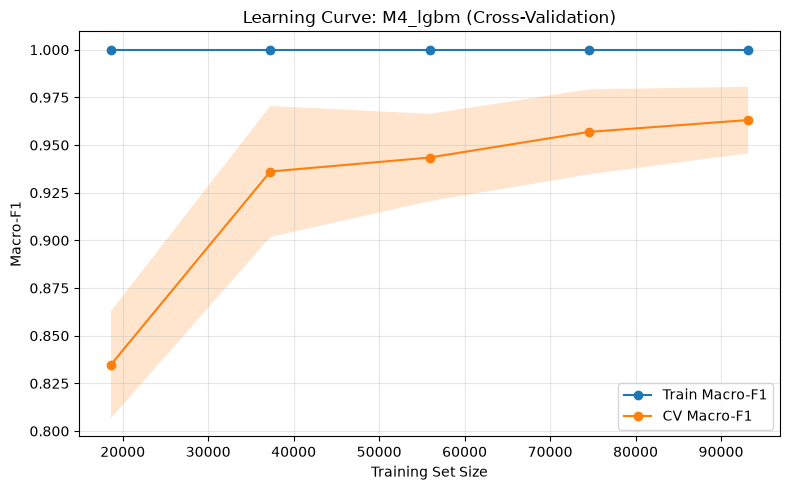

In [22]:
MACRO_F1_SCORER = make_scorer(f1_score, average="macro", labels=FAMILIES, zero_division=0)

print(f"Computing learning curve for {winner}...")
# Configure estimator with 2 threads and 4 parallel fold jobs (2x4 = 8 threads total)
pipe_lc = clone(fitted_models[winner])
pipe_lc.set_params(clf__n_jobs=2)

train_sizes, train_scores, val_scores = learning_curve(
    pipe_lc, X_train, y_train, 
    cv=get_cv(), 
    scoring=MACRO_F1_SCORER,
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=4
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Train Macro-F1")
ax.fill_between(train_sizes, train_scores.mean(1)-train_scores.std(1), 
                train_scores.mean(1)+train_scores.std(1), alpha=0.2)
ax.plot(train_sizes, val_scores.mean(axis=1), marker="o", label="CV Macro-F1")
ax.fill_between(train_sizes, val_scores.mean(1)-val_scores.std(1), 
                val_scores.mean(1)+val_scores.std(1), alpha=0.2)
ax.set_xlabel("Training Set Size")
ax.set_ylabel("Macro-F1")
ax.set_title(f"Learning Curve: {winner} (Cross-Validation)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p19_learning_curve.png", dpi=120)
plt.show()